# Data analysis

Results of the job `eda-v2` for the 100 image pairs.

In [1]:
import pandas as pd
from IPython.display import Image, display

stats = pd.read_csv("results/eda-v2/stats.csv")
columns = ["gt_mean", "input_mean", "gain", "gain_r", "gain_g", "gain_b", "gt_clipped", "input_black"]
stats.groupby("split")[columns].median().round(3)

,gt_mean,input_mean,gain,gain_r,gain_g,gain_b,gt_clipped,input_black
split,,,,,,,,
test,92.900,29.272,8.462,8.570,8.484,8.386,0.009,0.115
train,94.639,34.109,7.649,7.780,7.581,6.749,0.011,0.124
val,102.988,34.892,10.725,11.341,10.558,9.483,0.007,0.110


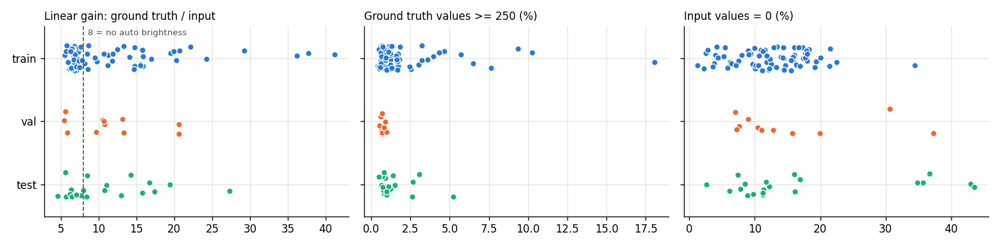

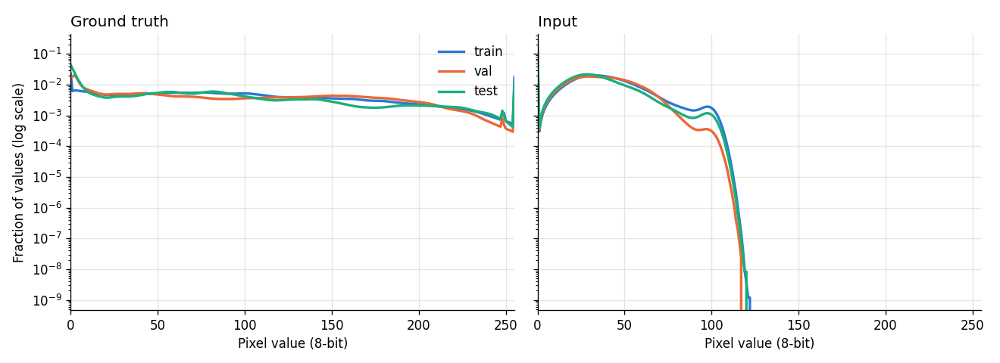

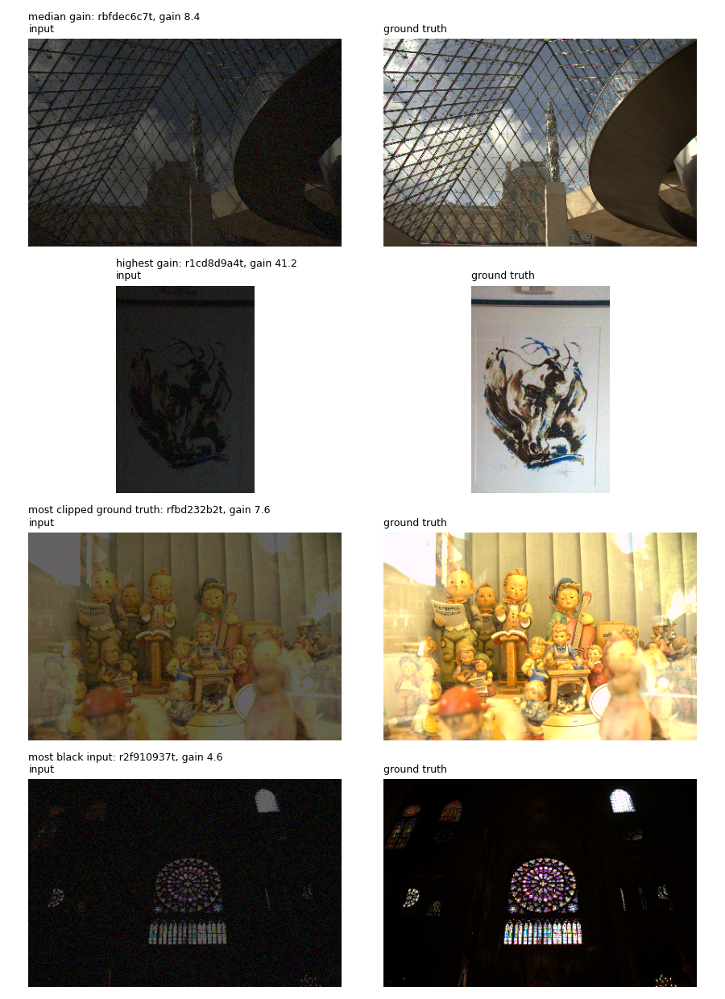

In [2]:
for name in ["per_image", "histograms", "samples"]:
    display(Image(f"results/eda-v2/{name}.png"))

# Baseline

Histogram equalization of the luma channel on the 20 test images (job `baseline-v1`).

,method,PSNR,SSIM,LPIPS
0,baseline,11.315,0.1524,1.0767


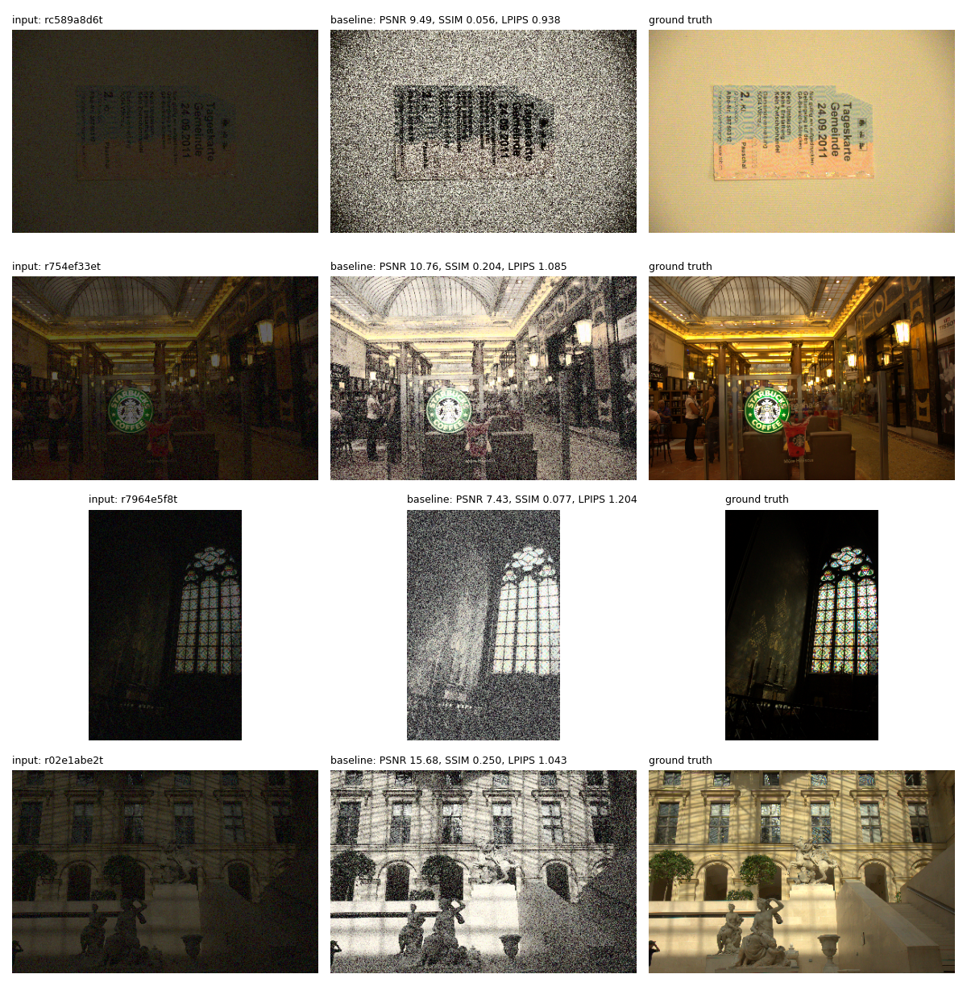

In [3]:
display(pd.read_csv("results/baseline-v1/summary.csv").round(4))
display(Image("results/baseline-v1/comparison.png"))

# Training

All networks predict a residual that is added to the input. Common settings: L1 loss, random patches 256 x 256 with
rotations and flips, batch size 16, Adam with lr 2e-4 and a cosine schedule, mixed precision. Each patch also gets a
128 x 128 thumbnail of its full input image. The model with the best validation PSNR is scored on the 20 test images
(full images, prediction on tiles 512 x 512).

| Codename | Model | Change |
|---|---|---|
| `train-v1a` | U-Net | base, 15000 steps |
| `train-v1b` | U-Net with a global branch | + global branch (thumbnail -> vector -> FiLM in the decoder) |
| `train-v1c` | NAFNet | other architecture, 15000 steps |
| `train-v2a` | U-Net with a global branch | 40000 steps |
| `train-v2b` | NAFNet with a global branch | + global branch, 15000 steps |

In [4]:
import matplotlib.pyplot as plt
import numpy as np

from data import METHOD_COLORS, _clean_axes

RUNS = ["train-v1a", "train-v1b", "train-v1c", "train-v2a", "train-v2b"]
summaries = pd.concat([pd.read_csv(f"results/{name}/summary.csv") for name in ["baseline-v1", *RUNS]]).set_index("method")
summaries.round(3)

,PSNR,SSIM,LPIPS,model,params,steps,best_val_psnr,train_hours,test_seconds
method,,,,,,,,,
baseline,11.315,0.152,1.077,NaN,NaN,NaN,NaN,NaN,NaN
train-v1a,19.782,0.398,0.520,unet,1925667.0,15000.0,21.419,0.589,56.580
train-v1b,24.068,0.587,0.346,unet-global,2093763.0,15000.0,27.959,0.664,50.639
train-v1c,20.953,0.631,0.384,nafnet,11575651.0,15000.0,22.220,2.607,79.566
train-v2a,26.004,0.716,0.271,unet-global,2093763.0,40000.0,30.775,1.645,47.078
train-v2b,24.706,0.719,0.286,nafnet-global,11810307.0,15000.0,30.138,3.016,82.519


## Main result

The table of the task: the baseline and the best network, `train-v2a` (best PSNR and LPIPS on the test set).

In [5]:
summaries.loc[["baseline", "train-v2a"], ["PSNR", "SSIM", "LPIPS"]].rename(index={"train-v2a": "network"}).round(3)

,PSNR,SSIM,LPIPS
method,,,
baseline,11.315,0.152,1.077
network,26.004,0.716,0.271


## Learning curves

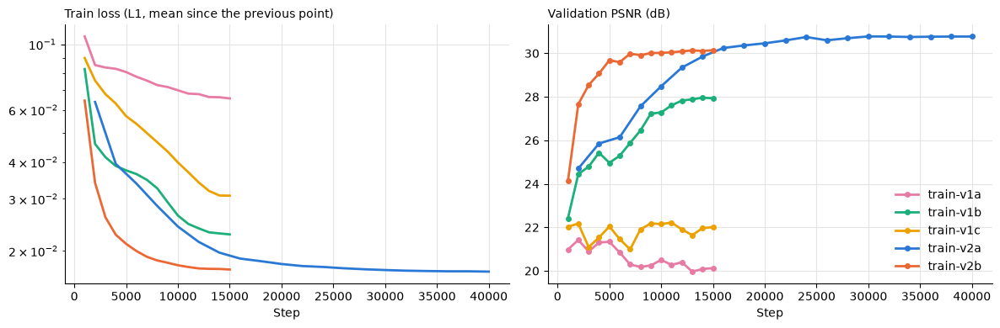

In [6]:
histories = {name: pd.read_csv(f"results/{name}/history.csv") for name in RUNS}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in histories.items():
    axes[0].plot(history["step"], history["train_loss"], color=METHOD_COLORS[name], linewidth=2, label=name)
    axes[1].plot(history["step"], history["val_psnr"], color=METHOD_COLORS[name], linewidth=2, marker="o",
                 markersize=4, label=name)
axes[0].set_yscale("log")
axes[0].set_title("Train loss (L1, mean since the previous point)", loc="left", fontsize=10)
axes[1].set_title("Validation PSNR (dB)", loc="left", fontsize=10)
for ax in axes:
    ax.set_xlabel("Step")
    _clean_axes(ax)
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig("results/summary/learning_curves.png", dpi=120, facecolor="white")

## Test images

PSNR of each test image. The label shows the linear gain of the ground truth over the input (`eda-v2`); 8 means the
same brightness as the input without the noise, more means that the auto brightness of the ground truth made the image
brighter.

Spearman correlation with the gain: {'baseline': 0.57, 'train-v2a': -0.08, 'train-v2b': -0.16}


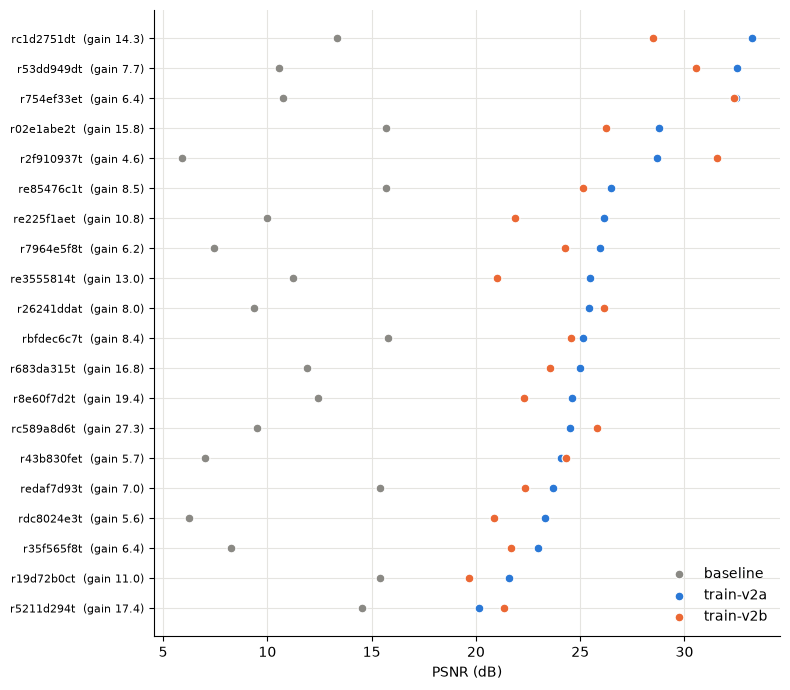

In [7]:
stats = pd.read_csv("results/eda-v2/stats.csv").set_index("file")
methods = {"baseline": "baseline-v1", "train-v2a": "train-v2a", "train-v2b": "train-v2b"}
per_image = pd.DataFrame({method: pd.read_csv(f"results/{run}/scores.csv").set_index("file")["PSNR"]
                          for method, run in methods.items()}).sort_values("train-v2a")
fig, ax = plt.subplots(figsize=(8, 7))
for method in methods:
    ax.scatter(per_image[method], range(len(per_image)), s=40, color=METHOD_COLORS[method], edgecolor="white",
               linewidth=0.8, label=method, zorder=3)
ax.set_yticks(range(len(per_image)), [f"{name}  (gain {stats.loc[name, 'gain']:.1f})" for name in per_image.index],
              fontsize=8)
ax.set_xlabel("PSNR (dB)")
_clean_axes(ax)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig("results/summary/per_image_psnr.png", dpi=120, facecolor="white")
print("Spearman correlation with the gain:",
      per_image.apply(lambda column: column.corr(stats.loc[per_image.index, "gain"], method="spearman")).round(2).to_dict())

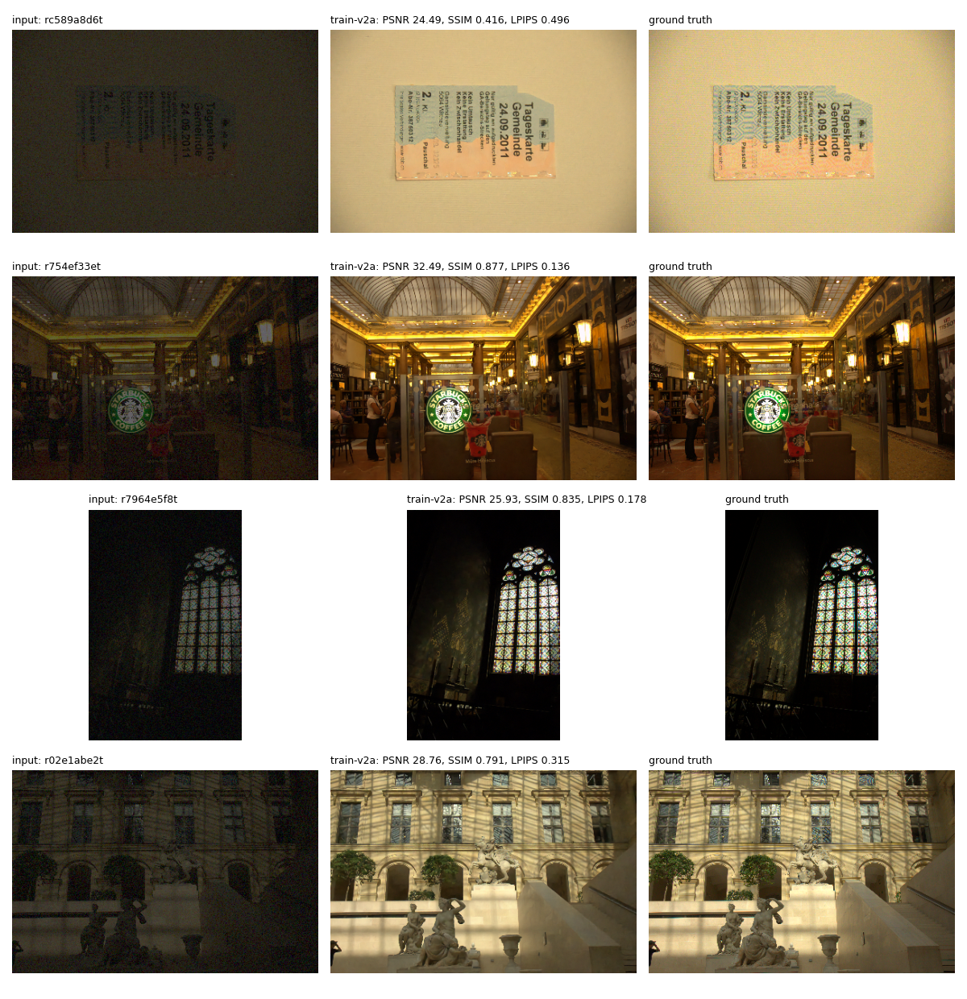

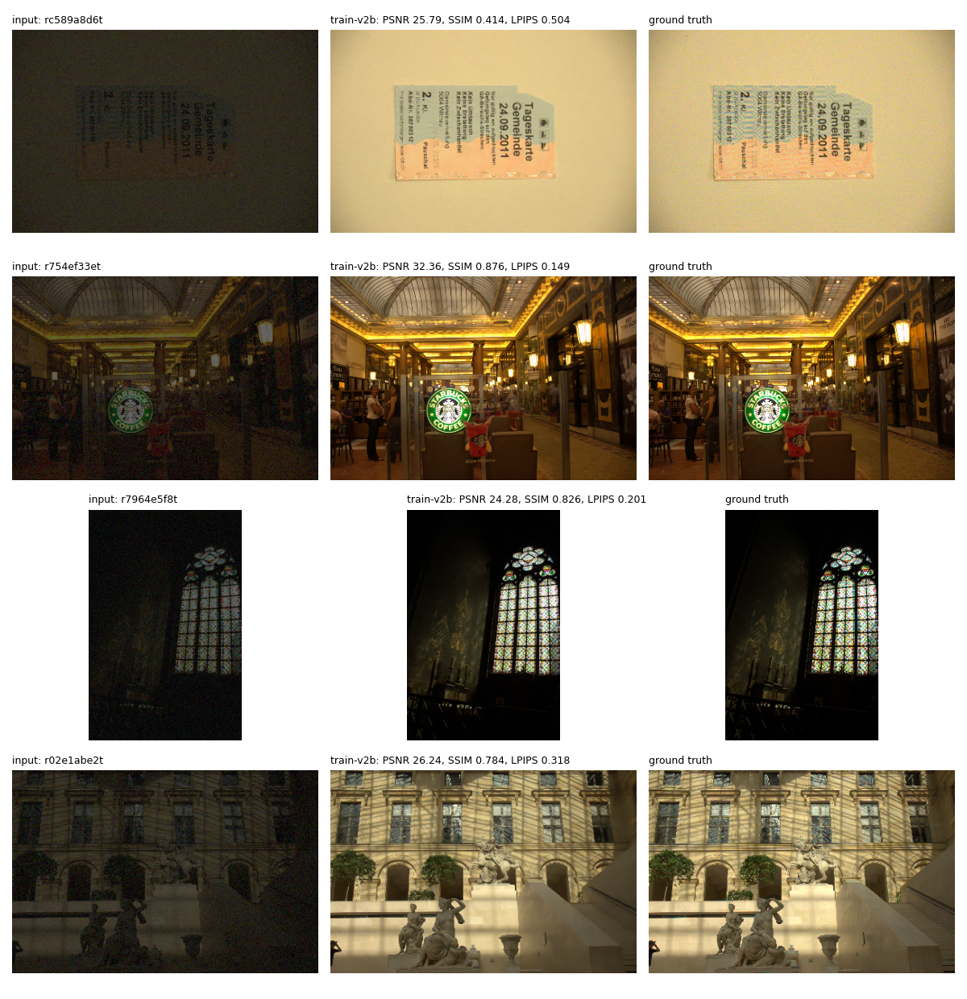

In [8]:
for name in ["train-v2a", "train-v2b"]:
    display(Image(f"results/{name}/comparison.png"))

## Observations

- The global branch gives the largest gain: +4.3 dB PSNR for U-Net (`train-v1a` -> `train-v1b`) and +3.8 dB for NAFNet
  (`train-v1c` -> `train-v2b`). Without it, the validation PSNR stops near 21-22 dB after a few thousand steps: a
  patch does not show how bright the full scene is, so the network cannot know the gain of the auto brightness.
- `train-v2a` (40000 steps) is the best network. Its validation PSNR stops at approximately 30.8 dB after 24000 steps,
  so a longer training does not help.
- NAFNet with the global branch learns faster for each step and has the best SSIM, but it has 5.6 times more
  parameters, and each step takes approximately 5 times longer than U-Net.
- The test PSNR is approximately 5 dB lower than the validation PSNR. The validation set is one photo session (11
  images), so it is a good set for the selection of the checkpoint, but not a good estimate of the test result.
- The networks are better than the baseline on all 20 test images. The PSNR of the baseline depends on the gain
  (Spearman 0.57), the PSNR of the networks does not (-0.08 and -0.16).


# Colors and clipped highlights

Results of the job `analysis-v1` on the 20 test images (code in `analysis.py`). The pixels of each image are split by the ground truth:

- shadows: luma < 0.1
- clipped: one channel >= 250
- highlights: luma >= 0.7 and not clipped
- midtones: all other pixels

`PSNR_gain_fit` is the PSNR after the best scale for each channel. The difference to `PSNR` is the part of the error that comes from the global exposure and the white balance.

In [9]:
analysis = pd.read_csv("results/analysis-v1/summary.csv", index_col="method")
columns = ["PSNR", "PSNR_gain_fit", "exposure_ratio", "cast_deg", "delta_e", "chroma_ratio", "clip_recall", "false_clip"]
analysis[columns].round(3)

,PSNR,PSNR_gain_fit,exposure_ratio,cast_deg,delta_e,chroma_ratio,clip_recall,false_clip
method,,,,,,,,
baseline,11.315,16.795,3.199,12.914,33.306,0.733,0.826,0.037
train-v2a,26.004,28.841,0.969,0.415,7.473,0.909,0.469,0.001
train-v2b,24.706,28.255,0.932,0.609,8.249,0.888,0.403,0.002


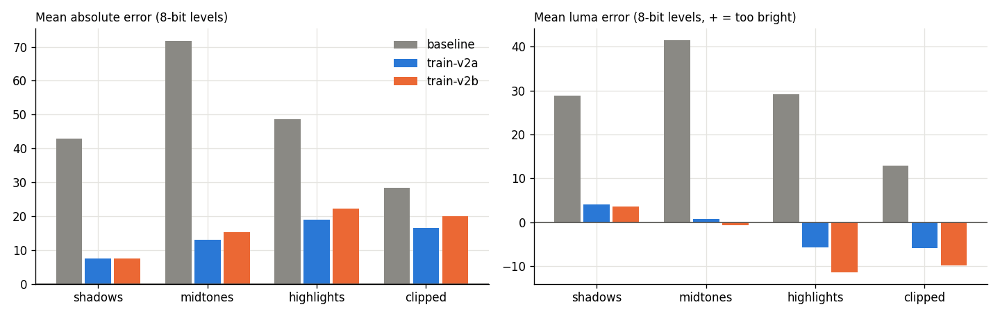

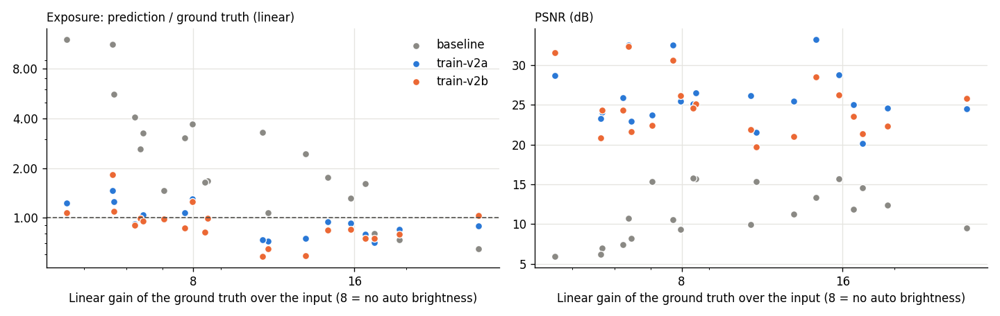

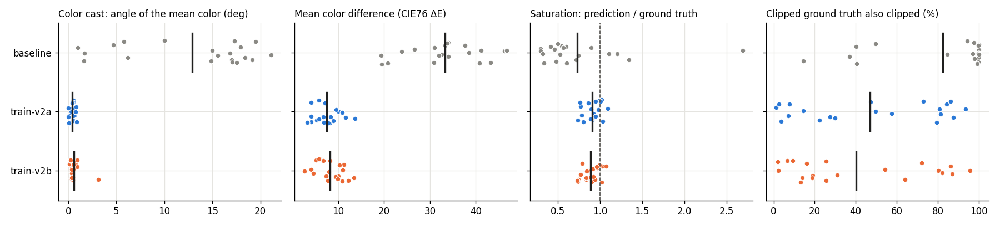

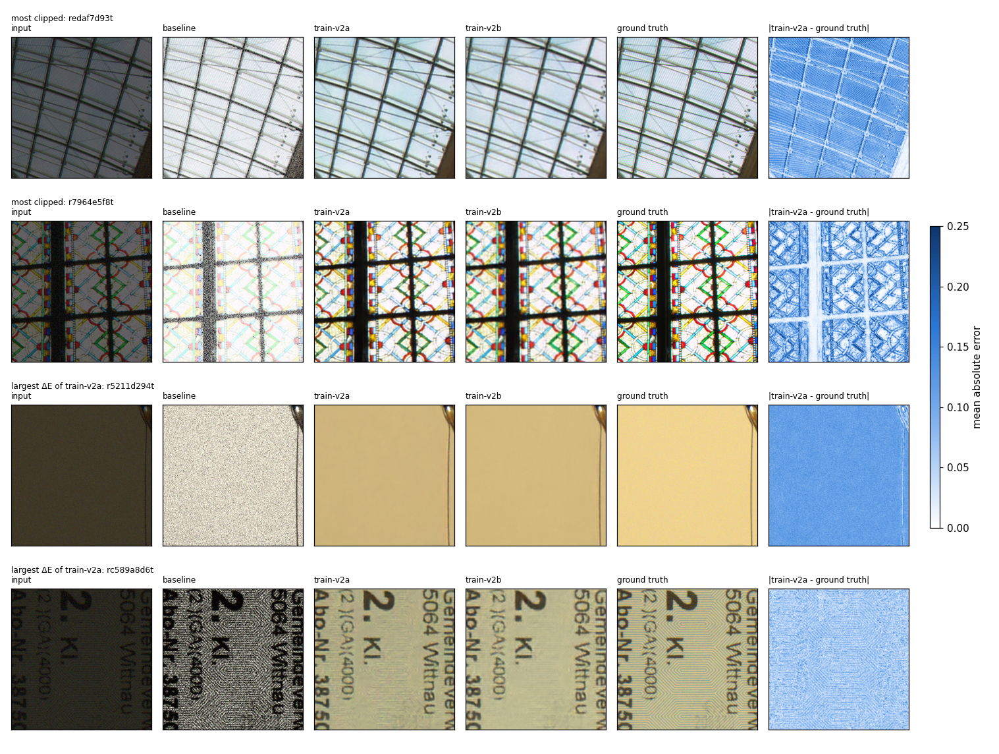

In [10]:
for name in ["regions", "exposure", "colors", "crops"]:
    display(Image(f"results/analysis-v1/{name}.png"))

## Observations

- The network keeps the colors: the mean color cast of `train-v2a` is 0.4 degrees (baseline: 12.9), and the mean ΔE is 7.5 (baseline: 33.3). The saturation is 91% of the ground truth, and only 74-79% on the most colorful and the most clipped scenes.
- The largest error of the network is the exposure of the scene. The exposure ratio decreases with the gain (Spearman -0.71). All 9 images with a gain >= 10 are too dark (0.71-0.94). Images with a gain < 8 are usually too bright (0.92-1.47).
- The worst images have an exposure error. After the gain fit, the PSNR of `r19d72b0ct` increases from 21.6 to 29.9 dB.
- The network keeps only 47% of the clipped pixels of the ground truth, and the highlights are approximately 6 levels too dark. It clips almost no other pixels (0.1%, baseline: 3.7%).
- The shadows are approximately 4 levels too bright. The finest textures (lines of the stained glass, the pattern on the ticket) are smooth in the output.